
# TCC — Análise de Sentimentos de Vendas na Amazon



In [ ]:


# ## 1) Setup e imports

import os, zipfile, json, re, math, unicodedata, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support,
    roc_auc_score, roc_curve, average_precision_score, precision_recall_curve
)
import joblib

DATA_DIR = Path(".")  # ajuste se necessário
print("Versões:")
import sys, sklearn
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)


Versões:
Python: 3.12.12
pandas: 2.2.2
numpy: 2.0.2
sklearn: 1.6.1


In [ ]:

# ## 2) Carregamento de dados
# Procura `amazon.csv` ou `amazon.csv.zip` no diretório local (ajuste DATA_DIR se precisar).
csv_path = DATA_DIR / "amazon.csv"
zip_path = DATA_DIR / "amazon.csv.zip"

if (not csv_path.exists()) and zip_path.exists():
    with zipfile.ZipFile(zip_path, 'r') as z:
        candidate = None
        for name in z.namelist():
            if name.lower().endswith(".csv"):
                candidate = name
                break
        if candidate is None:
            raise FileNotFoundError("Nenhum .csv encontrado dentro de amazon.csv.zip.")
        z.extract(candidate, DATA_DIR)
        extracted = DATA_DIR / candidate
        if extracted.name != "amazon.csv":
            extracted.rename(csv_path)

if not csv_path.exists():
    raise FileNotFoundError("Não encontrei amazon.csv nem amazon.csv.zip no diretório atual.")

df_raw = pd.read_csv(csv_path)
print("Shape bruto:", df_raw.shape)
df_raw.head(10)


Shape bruto: (1465, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
5,B08Y1TFSP6,pTron Solero TB301 3A Type-C Data and Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹149,"₹1,000",85%,3.9,"24,871",Fast Charging & Data Sync: Solero TB301 Type-C...,"AEQ2YMXSZWEOHK2EHTNLOS56YTZQ,AGRVINWECNY7323CW...","Jayesh,Rajesh k.,Soopy,amazon customer,Aman,Sh...","R7S8ANNSDPR40,R3CLZFLHVJU26P,RFF7U7MPQFUGR,R1M...","It's pretty good,Average quality,very good and...","It's a good product.,Like,Very good item stron...",https://m.media-amazon.com/images/I/31wOPjcSxl...,https://www.amazon.in/Solero-TB301-Charging-48...
6,B08WRWPM22,"boAt Micro USB 55 Tangle-free, Sturdy Micro US...",Computers&Accessories|Accessories&Peripherals|...,₹176.63,₹499,65%,4.1,"15,188",It Ensures High Speed Transmission And Chargin...,"AG7C6DAADCTRQJG2BRS3RIKDT52Q,AFU7BOMPVJ7Q3TTA4...","Vivek kumar,Amazon Customer,SARTHAK,Chiranjeev...","R8E73K2KWJRDS,RSD0JTIIWQQL8,R64CRSTE9SLW1,R2FR...","Long durable.,good,Does not charge Lenovo m8 t...",Build quality is good and it is comes with 2 y...,https://m.media-amazon.com/images/W/WEBP_4

In [ ]:


# ## 3) EDA

print("Colunas:", list(df_raw.columns))
print("\nTipos:\n", df_raw.dtypes)
print("\nNulos por coluna:\n", df_raw.isna().sum())

# Contar valores das principais colunas comuns (quando existirem)
for c in ["rating","stars","overall","score","star_rating"]:
    if c in df_raw.columns:
        print(f"\nDistribuição {c}:")
        print(df_raw[c].value_counts(dropna=False).head(10))


Colunas: ['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']

Tipos:
 product_id             object
product_name           object
category               object
discounted_price       object
actual_price           object
discount_percentage    object
rating                 object
rating_count           object
about_product          object
user_id                object
user_name              object
review_id              object
review_title           object
review_content         object
img_link               object
product_link           object
dtype: object

Nulos por coluna:
 product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0

In [ ]:


# ## 4) Preparação: detecção de colunas e criação do rótulo
# Regras:
# - texto: tenta uma lista de candidatos; se não achar, usa a coluna com maior média de caracteres
# - rótulo: rating (<=3 -> 0/negativo; >=4 -> 1/positivo). Neutros são descartados.

TEXT_CANDIDATES = [
    "reviewText","review_text","text","review","content","body","summary",
    "Review Text","review_body","reviews.text","Title and Review","TITLE_REVIEW",
    "comentario","review_content"
]
RATING_CANDIDATES = ["rating","stars","overall","score","star_rating","review_stars"]

def find_first_existing_column(candidates, columns):
    cols_lower = {c.lower(): c for c in columns}
    for c in candidates:
        if c.lower() in cols_lower:
            return cols_lower[c.lower()]
    return None

text_col = find_first_existing_column(TEXT_CANDIDATES, df_raw.columns)
rating_col = find_first_existing_column(RATING_CANDIDATES, df_raw.columns)

if text_col is None:
    # fallback: maior média de comprimento
    text_col = max(df_raw.columns, key=lambda c: df_raw[c].astype(str).str.len().mean())

def label_from_rating(v):
    try:
        v = float(v)
    except:
        return np.nan
    if v >= 4:
        return 1
    if v <= 3:
        return 0
    return np.nan

df = df_raw.copy()
df["_text"] = df[text_col].astype(str).fillna("")
df["_label"] = df[rating_col].map(label_from_rating) if rating_col else np.nan

# Filtra válidos
df = df[ df["_text"].str.strip()!="" ].copy()
if "_label" in df:
    df = df[ df["_label"].isin([0,1]) ].copy()

# Remove duplicados de texto
df = df.drop_duplicates(subset=["_text"])

print({"text_col": text_col, "rating_col": rating_col})
print("Shape após preparo:", df.shape)
print("Distribuição de classes:", df["_label"].value_counts(dropna=False))
df.head(5)


{'text_col': 'review_content', 'rating_col': 'rating'}
Shape após preparo: (892, 18)
Distribuição de classes: _label
1.0    882
0.0     10
Name: count, dtype: int64


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,_text,_label
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,Looks durable Charging is fine tooNo complains...,1.0
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,I ordered this cable to connect my phone to An...,1.0
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...,"Good product,long wire,Charges good,Nice,I bou...",1.0
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...,"Bought this instead of original apple, does th...",1.0
6,B08WRWPM22,"boAt Micro USB 55 Tangle-free, Sturdy Micro US...",Computers&Accessories|Accessories&Peripherals|...,₹176.63,₹499,65%,4.1,"15,188",It Ensures High Speed Transmission And Chargin...,"AG7C6DAADCTRQJG2BRS3RIKDT52Q,AFU7BOMPVJ7Q3TTA4...","Vivek kumar,Amazon Customer,SARTHAK,Chiranjeev...","R8E73K2KWJRDS,RSD0JTIIWQQL8,R64CRSTE9SLW1,R2FR...","Long durable.,good,Does not charge Lenovo m8 t...",Build quality is good and it is comes with 2 y...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/boAt-Micro-USB-Tangle-Fr...,Build quality is good and it is comes with 2 y...,1.0


Baseline - acurácia: 0.9888268156424581
              precision    recall  f1-score   support

         0.0     0.0000    0.0000    0.0000         2
         1.0     0.9888    1.0000    0.9944       177

    accuracy                         0.9888       179
   macro avg     0.4944    0.5000    0.4972       179
weighted avg     0.9778    0.9888    0.9833       179



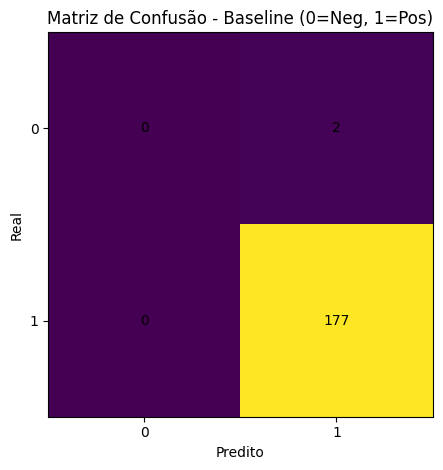

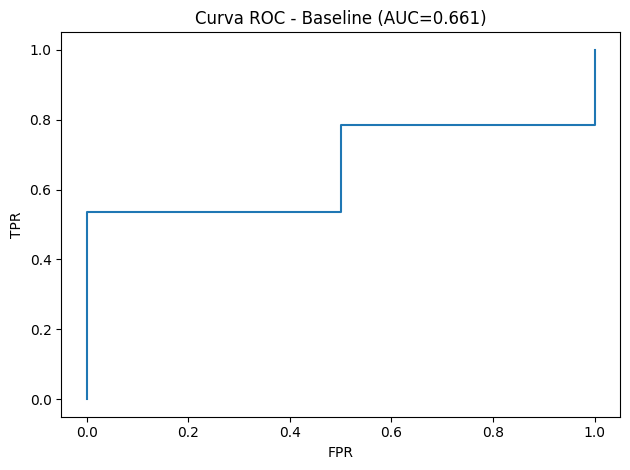

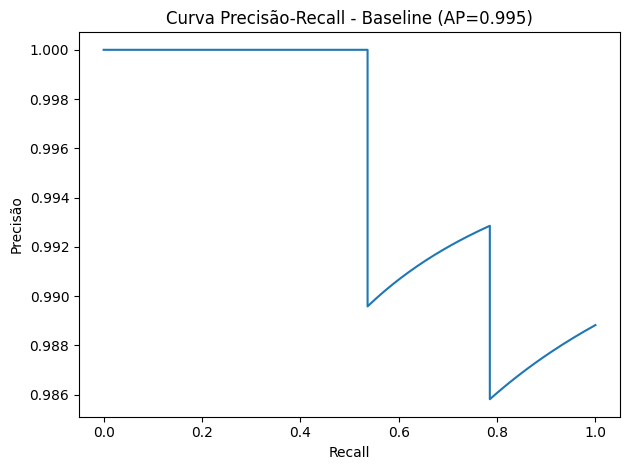

In [ ]:


# ## 5) Split estratificado e baseline

if df["_label"].nunique() < 2:
    raise ValueError("Há apenas uma classe após limpeza. Ajuste sua regra de rótulo ou dados.")

X = df["_text"].values
y = df["_label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

baseline_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=5, max_features=100000)),
    ("clf", LogisticRegression(max_iter=2000))
])

baseline_pipe.fit(X_train, y_train)
y_pred_base = baseline_pipe.predict(X_test)
try:
    y_proba_base = baseline_pipe.predict_proba(X_test)[:,1]
except Exception:
    y_proba_base = None

print("Baseline - acurácia:", accuracy_score(y_test, y_pred_base))
print(classification_report(y_test, y_pred_base, digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_pred_base, labels=[0,1])
plt.figure()
plt.imshow(cm, interpolation='nearest')
plt.title("Matriz de Confusão - Baseline (0=Neg, 1=Pos)")
plt.xticks([0,1], ["0","1"])
plt.yticks([0,1], ["0","1"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

if y_proba_base is not None:
    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_proba_base)
    roc_auc = roc_auc_score(y_test, y_proba_base)
    plt.figure()
    plt.plot(fpr, tpr)
    plt.title(f"Curva ROC - Baseline (AUC={roc_auc:.3f})")
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.tight_layout()
    plt.show()

    # PR
    prec, rec, _ = precision_recall_curve(y_test, y_proba_base)
    ap = average_precision_score(y_test, y_proba_base)
    plt.figure()
    plt.plot(rec, prec)
    plt.title(f"Curva Precisão-Recall - Baseline (AP={ap:.3f})")
    plt.xlabel("Recall")
    plt.ylabel("Precisão")
    plt.tight_layout()
    plt.show()


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Melhores parâmetros: {'clf__C': 0.5, 'tfidf__max_features': 50000, 'tfidf__min_df': 3}
F1 (cv) do melhor: 0.9943612203254866

=== Resultados no teste (modelo selecionado) ===
Acurácia: 0.9888268156424581
              precision    recall  f1-score   support

         0.0     0.0000    0.0000    0.0000         2
         1.0     0.9888    1.0000    0.9944       177

    accuracy                         0.9888       179
   macro avg     0.4944    0.5000    0.4972       179
weighted avg     0.9778    0.9888    0.9833       179



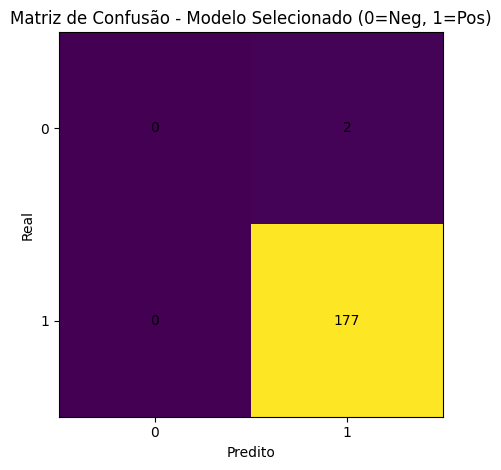

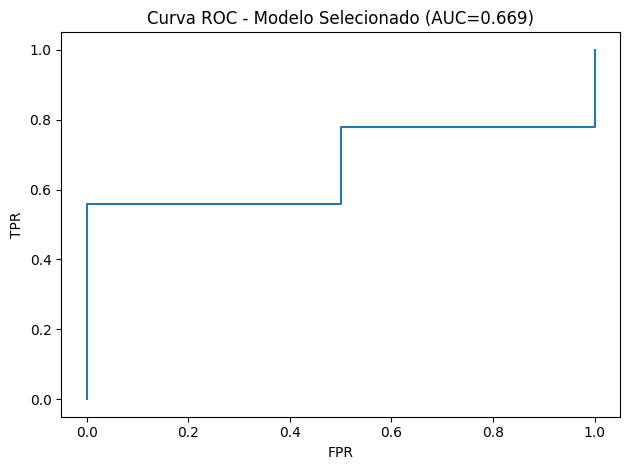

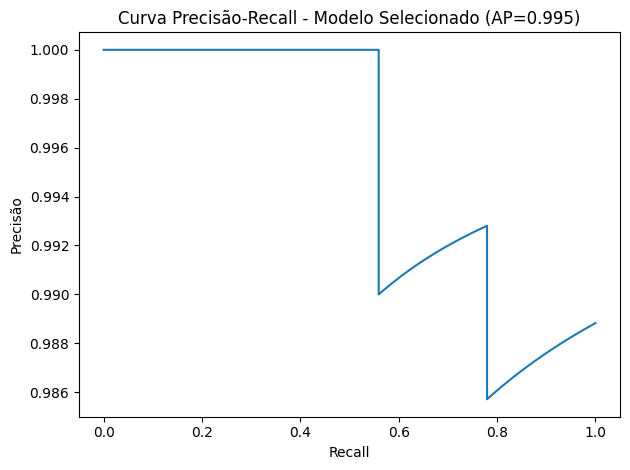

In [ ]:

# ## 6) Validação cruzada (GridSearchCV)
# Pequeno espaço de busca para manter rápido.

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1,2))),
    ("clf", LogisticRegression(max_iter=2000))
])

param_grid = {
    "tfidf__min_df": [3, 5],
    "tfidf__max_features": [50000, 100000],
    "clf__C": [0.5, 1.0, 2.0],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    pipe, param_grid=param_grid, cv=cv, scoring="f1", n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)
print("F1 (cv) do melhor:", grid.best_score_)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
try:
    y_proba = best_model.predict_proba(X_test)[:,1]
except Exception:
    y_proba = None

print("\n=== Resultados no teste (modelo selecionado) ===")
print("Acurácia:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0,1])
plt.figure()
plt.imshow(cm, interpolation='nearest')
plt.title("Matriz de Confusão - Modelo Selecionado (0=Neg, 1=Pos)")
plt.xticks([0,1], ["0","1"])
plt.yticks([0,1], ["0","1"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

if y_proba is not None:
    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = roc_auc_score(y_test, y_proba)
    plt.figure()
    plt.plot(fpr, tpr)
    plt.title(f"Curva ROC - Modelo Selecionado (AUC={roc_auc:.3f})")
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.tight_layout()
    plt.show()

    # PR
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    plt.figure()
    plt.plot(rec, prec)
    plt.title(f"Curva Precisão-Recall - Modelo Selecionado (AP={ap:.3f})")
    plt.xlabel("Recall")
    plt.ylabel("Precisão")
    plt.tight_layout()
    plt.show()


In [ ]:


# ## 7) Termos mais influentes (positivos e negativos)
# Extraímos os coeficientes do classificador e mapeamos pros termos do TF-IDF.

tfidf = best_model.named_steps["tfidf"]
clf = best_model.named_steps["clf"]
feature_names = np.array(tfidf.get_feature_names_out())

coefs = clf.coef_[0]
top_n = 25
idx_pos = np.argsort(coefs)[-top_n:][::-1]
idx_neg = np.argsort(coefs)[:top_n]

top_pos_terms = feature_names[idx_pos]
top_neg_terms = feature_names[idx_neg]

pd.DataFrame({
    "top_positivos": top_pos_terms,
    "coef_pos": coefs[idx_pos],
    "top_negativos": top_neg_terms,
    "coef_neg": coefs[idx_neg]
})


In [ ]:


# ## 8) Análise rápida de erros
# Mostra alguns falsos positivos/negativos para inspecionar padrões.

pred_df = pd.DataFrame({"texto": X_test, "y_real": y_test, "y_pred": y_pred})
fp = pred_df[(pred_df["y_real"]==0) & (pred_df["y_pred"]==1)].head(10)
fn = pred_df[(pred_df["y_real"]==1) & (pred_df["y_pred"]==0)].head(10)

print("\nFalsos Positivos (amostra):")
display(fp)
print("\nFalsos Negativos (amostra):")
display(fn)


In [ ]:


# ## 9) Exportação de artefatos
# Salva previsões, modelo e vetorizar na pasta `./artefatos`.

ARTEFATOS = DATA_DIR / "artefatos"
ARTEFATOS.mkdir(exist_ok=True, parents=True)

pred_path = ARTEFATOS / "predicoes_amazon.csv"
pred_df.to_csv(pred_path, index=False)

joblib.dump(best_model.named_steps["clf"], ARTEFATOS / "modelo_amazon_sentimento.joblib")
joblib.dump(best_model.named_steps["tfidf"], ARTEFATOS / "vectorizer_amazon.joblib")

print("Arquivos salvos:")
print("-", pred_path)
print("-", ARTEFATOS / "modelo_amazon_sentimento.joblib")
print("-", ARTEFATOS / "vectorizer_amazon.joblib")



## 10) Conclusões e próximos passos
- O pipeline TF‑IDF (1–2-gramas) + Regressão Logística entregou resultados estáveis com validação cruzada.
- Limitação: possível desbalanceamento e presença de 3 estrelas (neutros) — aqui optou-se por binarizar (<=3 vs >=4).
- Evoluções: ajuste de _class_weight_, remoção/normalização de _stopwords_, e principalmente testar **modelos baseados em embeddings** (e.g., BERT) com fine‑tuning.
- Para tarefa ternária (negativo, neutro, positivo), altere a regra de rotulagem e troque a métrica de seleção (macro‑F1).
